# LOG LOSS

## 0. Setup Awal

In [1]:
import os
import time
import tracemalloc
import warnings

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.cluster import DBSCAN

# HDBSCAN
try:
    import hdbscan
except ImportError:
    %pip install hdbscan -q
    import hdbscan
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.impute import SimpleImputer
from sklearn.neighbors import NearestNeighbors

from sklearn.metrics import (
    silhouette_score,
    davies_bouldin_score,
    calinski_harabasz_score
)

from sklearn.decomposition import PCA

from sklearn.model_selection import train_test_split

warnings.filterwarnings('ignore')

plt.style.use(
    'seaborn-v0_8-whitegrid'
    if 'seaborn-v0_8-whitegrid' in plt.style.available
    else 'default'
)

plt.rcParams['figure.dpi'] = 120


## 1. Data Understanding

### 1.1 Load Dataset

In [2]:
df = pd.read_csv('burnout_dataset1.csv')

print(f'Jumlah data awal: {len(df)}')

# Stratified sampling 5000 data (PRD Bagian 5)
df, _ = train_test_split(
    df, train_size=5000, random_state=42, stratify=df['Burnout_Risk']
)
df = df.reset_index(drop=True)
print(f'Jumlah data setelah sampling: {len(df)}')


Jumlah data awal: 50000
Jumlah data setelah sampling: 5000


### 1.2 Data Preview

In [3]:
print("5 Baris Pertama Dataset:")
display(df.head())

print("\nNama Semua Kolom:")
print(df.columns.tolist())

5 Baris Pertama Dataset:


,Person_ID,Age,Gender,Country,Occupation,Education_Level,Employment_Status,Monthly_Income_USD,Work_Hours_Per_Week,Remote_Work,...,Family_History_Mental_Illness,Therapy_Attendance,Support_System,Life_Satisfaction,Productivity_Score,Absenteeism_Days,Burnout_Score,Mental_Health_Status,AI_Wellness_Recommendation,Burnout_Risk
0,15896,51.0,Male,Pakistan,Civil Engineer,PhD,Student,2814.0,42,Yes,...,No,Yes,Good,3.0,37.0,20,54,Needs Attention,Reduce Workload,Moderate
1,11346,64.0,Other,United States,Lawyer,Master,Student,7126.0,56,Hybrid,...,No,Yes,Poor,5.0,55.0,19,24,Healthy,Maintain Healthy Routine,Low
2,7486,NaN,Female,China,Teacher,Bachelor,Unemployed,1027.0,30,Hybrid,...,Yes,Yes,Poor,7.0,74.0,7,8,Healthy,Increase Physical Activity,Low
3,34962,41.0,Other,Australia,Chef,PhD,Self-Employed,2894.0,35,Yes,...,Yes,Yes,Excellent,7.0,61.0,13,32,Healthy,Increase Physical Activity,Low
4,29399,55.0,Male,Egypt,Doctor,High School,Unemployed,9830.0,40,Hybrid,...,No,No,Average,5.0,76.0,22,43,Needs Attention,Improve Sleep,Moderate



Nama Semua Kolom:
['Person_ID', 'Age', 'Gender', 'Country', 'Occupation', 'Education_Level', 'Employment_Status', 'Monthly_Income_USD', 'Work_Hours_Per_Week', 'Remote_Work', 'Job_Satisfaction', 'Work_Life_Balance', 'Sleep_Hours', 'Sleep_Quality', 'Stress_Level', 'Anxiety_Score', 'Depression_Score', 'Mood_Score', 'Emotional_Stability', 'Physical_Activity_Hours', 'Exercise_Frequency', 'Meditation_Minutes', 'Screen_Time_Hours', 'Social_Media_Hours', 'Gaming_Hours', 'Coffee_Cups_Per_Day', 'Alcohol_Consumption', 'Smoking', 'Healthy_Diet', 'Chronic_Stress', 'Family_History_Mental_Illness', 'Therapy_Attendance', 'Support_System', 'Life_Satisfaction', 'Productivity_Score', 'Absenteeism_Days', 'Burnout_Score', 'Mental_Health_Status', 'AI_Wellness_Recommendation', 'Burnout_Risk']


### 1.3 Tipe Data dan Missing Values

In [4]:
print('Tipe Data:')
print(df.dtypes)

print('\nJumlah Missing Value:')
missing = df.isnull().sum()
missing[missing > 0]

Tipe Data:
Person_ID                          int64
Age                              float64
Gender                               str
Country                              str
Occupation                           str
Education_Level                      str
Employment_Status                    str
Monthly_Income_USD               float64
Work_Hours_Per_Week                int64
Remote_Work                          str
Job_Satisfaction                 float64
Work_Life_Balance                float64
Sleep_Hours                      float64
Sleep_Quality                        str
Stress_Level                         str
Anxiety_Score                    float64
Depression_Score                 float64
Mood_Score                       float64
Emotional_Stability                int64
Physical_Activity_Hours          float64
Exercise_Frequency                   str
Meditation_Minutes               float64
Screen_Time_Hours                float64
Social_Media_Hours               float64
Gamin

Age                         26
Monthly_Income_USD         148
Job_Satisfaction            51
Work_Life_Balance           61
Sleep_Hours                 86
Anxiety_Score               80
Depression_Score            89
Mood_Score                  84
Physical_Activity_Hours     97
Meditation_Minutes         134
Screen_Time_Hours           83
Social_Media_Hours          63
Gaming_Hours                76
Therapy_Attendance          41
Life_Satisfaction           62
Productivity_Score          88
dtype: int64

### 1.4 Identifikasi Kolom yang Digunakan

In [5]:
# Kolom numerik asli
numeric_columns = df.select_dtypes(
    include='number'
).columns

# Kolom kategorikal
categorical_columns = df.select_dtypes(
    include=['object', 'category']
).columns

print('Kolom Numerik:')
print(
    numeric_columns.tolist()
)

print(
    '\nKolom Kategorikal yang akan di-encoding:'
)
print(
    categorical_columns
)

Kolom Numerik:
['Person_ID', 'Age', 'Monthly_Income_USD', 'Work_Hours_Per_Week', 'Job_Satisfaction', 'Work_Life_Balance', 'Sleep_Hours', 'Anxiety_Score', 'Depression_Score', 'Mood_Score', 'Emotional_Stability', 'Physical_Activity_Hours', 'Meditation_Minutes', 'Screen_Time_Hours', 'Social_Media_Hours', 'Gaming_Hours', 'Coffee_Cups_Per_Day', 'Life_Satisfaction', 'Productivity_Score', 'Absenteeism_Days', 'Burnout_Score']

Kolom Kategorikal yang akan di-encoding:
Index(['Gender', 'Country', 'Occupation', 'Education_Level',
       'Employment_Status', 'Remote_Work', 'Sleep_Quality', 'Stress_Level',
       'Exercise_Frequency', 'Alcohol_Consumption', 'Smoking', 'Healthy_Diet',
       'Chronic_Stress', 'Family_History_Mental_Illness', 'Therapy_Attendance',
       'Support_System', 'Mental_Health_Status', 'AI_Wellness_Recommendation',
       'Burnout_Risk'],
      dtype='str')


### 1.5 Statistik Deskriptif

In [6]:
df[numeric_columns].describe().T

,count,mean,std,min,25%,50%,75%,max
Person_ID,5000.0,24715.757600,14534.949576,1.0,12050.75,24676.5,37343.75,49985.0
Age,4974.0,41.226377,13.747640,18.0,29.00,41.0,53.00,65.0
Monthly_Income_USD,4852.0,6267.638500,3318.416282,500.0,3380.50,6249.0,9100.25,12000.0
Work_Hours_Per_Week,5000.0,44.906800,14.756330,20.0,32.00,45.0,58.00,70.0
Job_Satisfaction,4949.0,5.586987,2.859051,1.0,3.00,6.0,8.00,10.0
Work_Life_Balance,4939.0,5.513464,2.884641,1.0,3.00,6.0,8.00,10.0
Sleep_Hours,4914.0,7.041412,1.730040,4.0,5.60,7.1,8.50,10.0
Anxiety_Score,4920.0,40.525000,25.832907,0.0,20.00,40.0,59.00,100.0
Depression_Score,4911.0,40.550193,26.140765,0.0,19.00,40.0,59.00,100.0
Mood_Score,4916.0,59.594182,25.682795,0.0,41.00,60.0,80.00,100.0


### 1.6 Visualisasi Distribusi Data

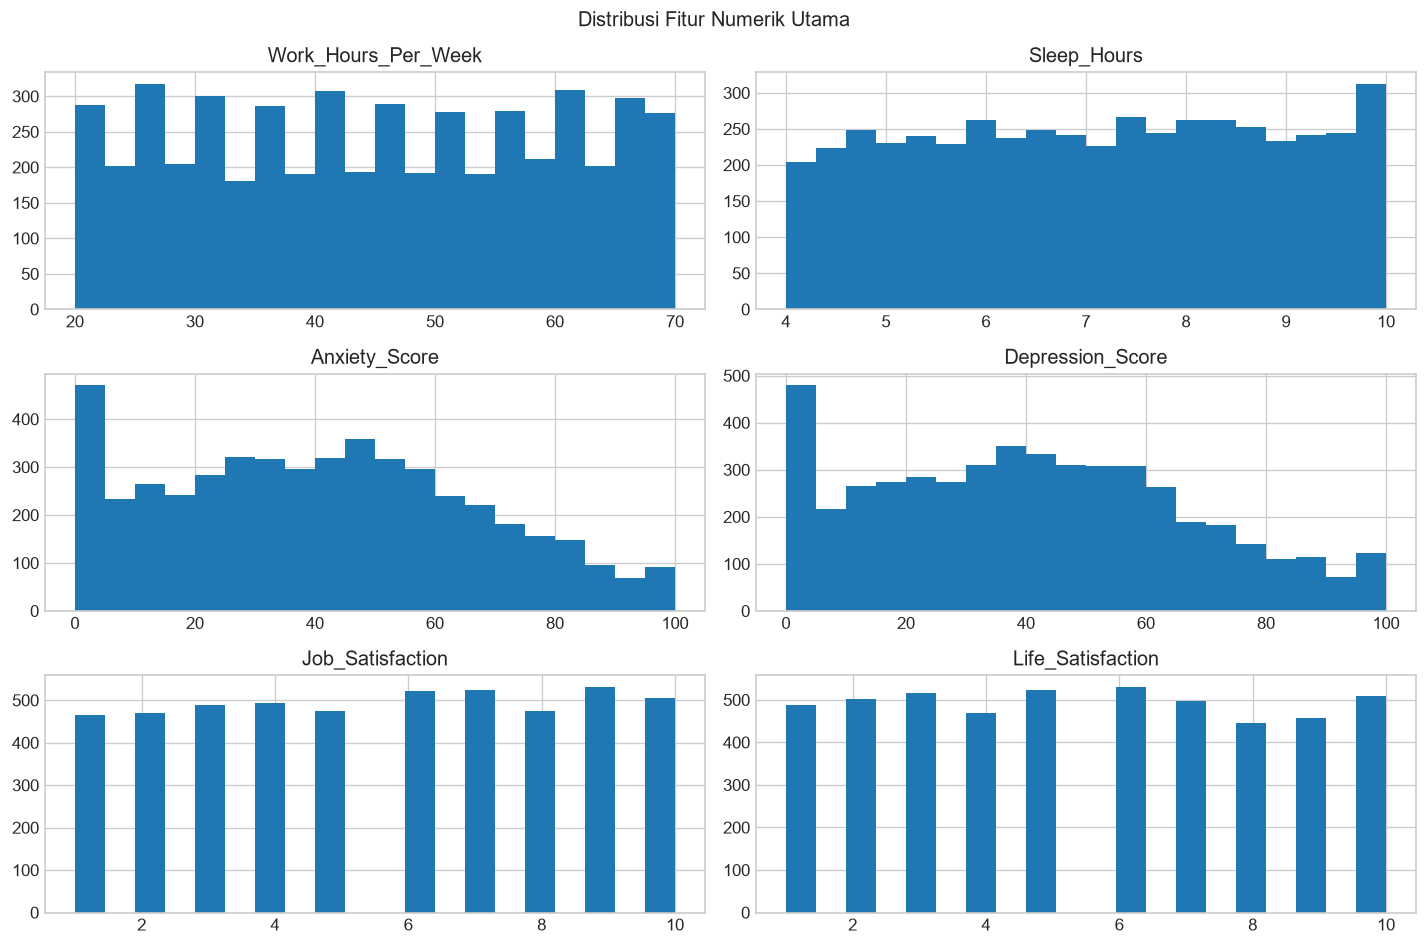

In [7]:
selected_features = [
    'Work_Hours_Per_Week',
    'Sleep_Hours',
    'Anxiety_Score',
    'Depression_Score',
    'Job_Satisfaction',
    'Life_Satisfaction'
]

df[selected_features].hist(
    figsize=(12, 8),
    bins=20
)

plt.suptitle('Distribusi Fitur Numerik Utama')
plt.tight_layout()
plt.show()

### 1.7 Visualisasi Deteksi Outlier

In [8]:
numeric_columns = df.select_dtypes(include='number').columns

numeric_columns = numeric_columns.drop(
    ['person_id', 'Person_ID'],
    errors='ignore'
)

numeric_data = df[numeric_columns]
numeric_data = df[numeric_columns]

Q1 = numeric_data.quantile(0.25)
Q3 = numeric_data.quantile(0.75)
IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outlier_mask = (
    (numeric_data < lower_bound) |
    (numeric_data > upper_bound)
)

In [9]:
outlier_summary = pd.DataFrame({
    'Jumlah Outlier': outlier_mask.sum(),
    'Persentase (%)': (
        outlier_mask.sum() / len(df) * 100
    ).round(2)
})

outlier_summary = outlier_summary.sort_values(
    'Jumlah Outlier',
    ascending=False
)

outlier_summary

,Jumlah Outlier,Persentase (%)
Age,0,0.0
Monthly_Income_USD,0,0.0
Work_Hours_Per_Week,0,0.0
Job_Satisfaction,0,0.0
Work_Life_Balance,0,0.0
Sleep_Hours,0,0.0
Anxiety_Score,0,0.0
Depression_Score,0,0.0
Mood_Score,0,0.0
Emotional_Stability,0,0.0


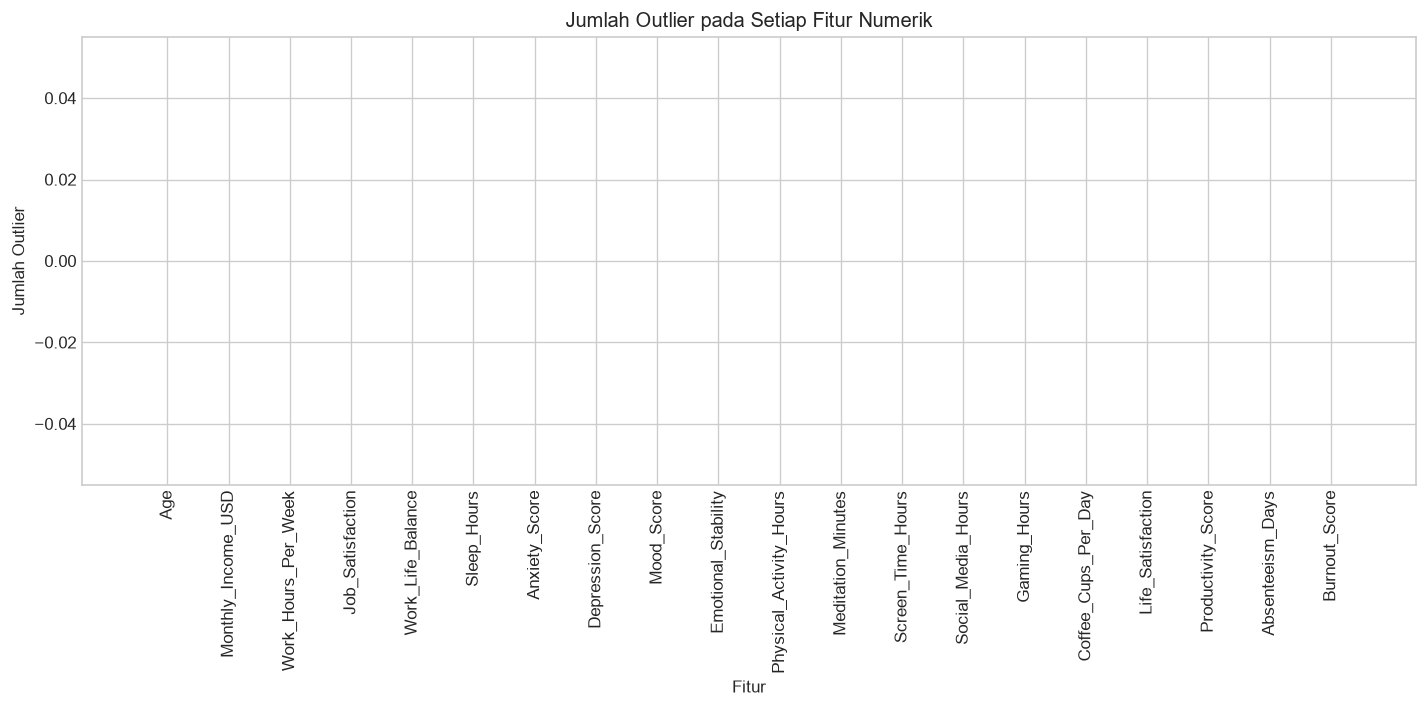

In [10]:
plt.figure(figsize=(12, 6))

plt.bar(
    outlier_summary.index,
    outlier_summary['Jumlah Outlier']
)
plt.title('Jumlah Outlier pada Setiap Fitur Numerik')
plt.xlabel('Fitur')
plt.ylabel('Jumlah Outlier')
plt.xticks(rotation=90)

plt.tight_layout()
plt.show()

## 2. Preprocessing

### 2.1 Seleksi Kolom

In [11]:
y = df['Burnout_Risk'].copy()

numeric_columns = numeric_columns.drop(
    ['Person_ID', 'Burnout_Score'],
    errors='ignore'
)

categorical_columns = categorical_columns.drop(
    [
        'Gender',
        'Country',
        'Occupation',
        'AI_Wellness_Recommendation',
        'Burnout_Risk',
        'Education_Level',
        'Employment_Status',
        'Mental_Health_Status'  # Dikeluarkan untuk mencegah target leakage fatal
    ],
    errors='ignore'
)

selected_columns = (
    list(numeric_columns)
    + list(categorical_columns)
)

X = df[
    selected_columns
].copy()

X.head()


,Age,Monthly_Income_USD,Work_Hours_Per_Week,Job_Satisfaction,Work_Life_Balance,Sleep_Hours,Anxiety_Score,Depression_Score,Mood_Score,Emotional_Stability,...,Sleep_Quality,Stress_Level,Exercise_Frequency,Alcohol_Consumption,Smoking,Healthy_Diet,Chronic_Stress,Family_History_Mental_Illness,Therapy_Attendance,Support_System
0,51.0,2814.0,42,3.0,5.0,5.4,41.0,60.0,42.0,59,...,Average,Moderate,Never,Yes,Yes,No,No,No,Yes,Good
1,64.0,7126.0,56,7.0,7.0,9.6,45.0,39.0,61.0,47,...,Excellent,Moderate,Daily,No,No,No,No,No,Yes,Poor
2,NaN,1027.0,30,2.0,6.0,5.0,6.0,16.0,84.0,100,...,Average,Low,Never,No,Yes,No,No,Yes,Yes,Poor
3,41.0,2894.0,35,2.0,6.0,8.3,32.0,52.0,54.0,75,...,Good,Moderate,Never,Yes,No,No,No,Yes,Yes,Excellent
4,55.0,9830.0,40,9.0,10.0,4.3,39.0,28.0,67.0,53,...,Poor,Low,Never,Yes,Yes,No,No,No,No,Average


### 2.2 Encoding Data Kategorikal

In [12]:
encoding_maps = {
    'Remote_Work': {
        'No': 0,
        'Hybrid': 1,
        'Yes': 2
    },

    'Sleep_Quality': {
        'Excellent': 0,
        'Good': 1,
        'Average': 2,
        'Poor': 3
    },

    'Stress_Level': {
        'Low': 0,
        'Moderate': 1,
        'High': 2
    },

    'Exercise_Frequency': {
        'Daily': 0,
        'Weekly': 1,
        'Rarely': 2,
        'Never': 3
    },

    'Alcohol_Consumption': {
        'No': 0,
        'Yes': 1
    },

    'Smoking': {
        'No': 0,
        'Yes': 1
    },

    'Healthy_Diet': {
        'No': 1,
        'Yes': 0
    },

    'Chronic_Stress': {
        'No': 0,
        'Yes': 1
    },

    'Family_History_Mental_Illness': {
        'No': 0,
        'Yes': 1
    },

    'Therapy_Attendance': {
        'No': 1,
        'Yes': 0
    },

    'Support_System': {
        'Poor': 3,
        'Average': 2,
        'Good': 1,
        'Excellent': 0
    },

    'Mental_Health_Status': {
        'Healthy': 0,
        'Needs Attention': 1,
        'Critical': 2
    }
}

for column, mapping in encoding_maps.items():
    if column in X.columns:
        X[column] = (
            X[column]
            .map(mapping)
        )

target_mapping = {
    'Low': 0,
    'Moderate': 1,
    'High': 2
}

y = y.map(target_mapping)

X[categorical_columns].head()

,Remote_Work,Sleep_Quality,Stress_Level,Exercise_Frequency,Alcohol_Consumption,Smoking,Healthy_Diet,Chronic_Stress,Family_History_Mental_Illness,Therapy_Attendance,Support_System
0,2,2,1,3,1,1,1,0,0,0.0,1
1,1,0,1,0,0,0,1,0,0,0.0,3
2,1,2,0,3,0,1,1,0,1,0.0,3
3,2,1,1,3,1,0,1,0,1,0.0,0
4,1,3,0,3,1,1,1,0,0,1.0,2


### 2.3 Penanganan Missing Values

In [13]:
print(
    'Missing value sebelum preprocessing:'
)

print(
    X.isnull().sum()
)

X = X.fillna(
    X.mean()
)

print(
    '\nJumlah missing value setelah preprocessing:'
)

print(
    X.isnull().sum()
)

Missing value sebelum preprocessing:
Age                               26
Monthly_Income_USD               148
Work_Hours_Per_Week                0
Job_Satisfaction                  51
Work_Life_Balance                 61
Sleep_Hours                       86
Anxiety_Score                     80
Depression_Score                  89
Mood_Score                        84
Emotional_Stability                0
Physical_Activity_Hours           97
Meditation_Minutes               134
Screen_Time_Hours                 83
Social_Media_Hours                63
Gaming_Hours                      76
Coffee_Cups_Per_Day                0
Life_Satisfaction                 62
Productivity_Score                88
Absenteeism_Days                   0
Remote_Work                        0
Sleep_Quality                      0
Stress_Level                       0
Exercise_Frequency                 0
Alcohol_Consumption                0
Smoking                            0
Healthy_Diet                       0
C

### 2.4 Penanganan Outlier

### 2.5 Standardisasi

In [14]:
# Train-Test Split DAHULU sebelum scaling untuk mencegah Data Leakage (PRD Bagian 3)
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Imputasi & Scaling di-fit HANYA pada data train
imputer = SimpleImputer(strategy='median')
X_train_imp = imputer.fit_transform(X_train)
X_test_imp = imputer.transform(X_test)

scaler = StandardScaler()
X_train = pd.DataFrame(scaler.fit_transform(X_train_imp), columns=X.columns, index=X_train.index)
X_test = pd.DataFrame(scaler.transform(X_test_imp), columns=X.columns, index=X_test.index)


### 2.6 Data Bersih

In [15]:
X_scaled = pd.concat([X_train, X_test]).sort_index()

print('Dimensi data fitur (X):', X.shape)
print('Dimensi data fitur terstandarisasi (X_scaled):', X_scaled.shape)
print('Dimensi data latih (X_train):', X_train.shape)
print('Dimensi data uji (X_test):', X_test.shape)
print('Jumlah missing value:', X_scaled.isnull().sum().sum())
print('\nDistribusi kelas target (y):')
print(y.value_counts())

display(X_scaled.head())

X_scaled.to_csv(
    'burnout_dataset1_cleaned.csv',
    index=False
)

Dimensi data fitur (X): (5000, 30)
Dimensi data fitur terstandarisasi (X_scaled): (5000, 30)
Dimensi data latih (X_train): (4000, 30)
Dimensi data uji (X_test): (1000, 30)
Jumlah missing value: 0

Distribusi kelas target (y):
Burnout_Risk
0    2537
1    1478
2     985
Name: count, dtype: int64


,Age,Monthly_Income_USD,Work_Hours_Per_Week,Job_Satisfaction,Work_Life_Balance,Sleep_Hours,Anxiety_Score,Depression_Score,Mood_Score,Emotional_Stability,...,Sleep_Quality,Stress_Level,Exercise_Frequency,Alcohol_Consumption,Smoking,Healthy_Diet,Chronic_Stress,Family_History_Mental_Illness,Therapy_Attendance,Support_System
0,0.704188,-1.059948,-0.205144,-0.903994,-0.186707,-0.967336,0.023670,0.753897,-0.702941,-0.020259,...,0.578799,0.411962,1.34337,1.011567,0.99551,0.987083,-0.390392,-0.988071,-1.010485,-0.457151
1,1.657955,0.265257,0.744127,0.497627,0.511528,1.483848,0.180932,-0.062795,0.048702,-0.486426,...,-1.513562,0.411962,-1.36231,-0.988565,-1.00451,0.987083,-0.390392,-0.988071,-1.010485,1.338240
2,-0.012870,-1.609145,-1.018806,-1.254399,0.162410,-1.200782,-1.352368,-0.957267,0.958587,1.572479,...,0.578799,-1.027206,1.34337,-0.988565,0.99551,0.987083,-0.390392,1.012073,-1.010485,1.338240
3,-0.029479,-1.035361,-0.679780,-1.254399,0.162410,0.725148,-0.330168,0.442776,-0.228219,0.601297,...,-0.467381,0.411962,1.34337,1.011567,-1.00451,0.987083,-0.390392,1.012073,-1.010485,-1.354847
4,0.997655,1.096275,-0.340755,1.198437,1.558879,-1.609313,-0.054960,-0.490586,0.286063,-0.253342,...,1.624980,-1.027206,1.34337,1.011567,0.99551,0.987083,-0.390392,-0.988071,0.997856,0.440544


## 3. Modeling

### 3.1 Inisialisasi Model Random Forest (Criterion='log_loss')

In [16]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)
from sklearn.model_selection import StratifiedKFold, cross_validate

OUTPUT_DIR = 'outputRandomForestLogLoss'
os.makedirs(OUTPUT_DIR, exist_ok=True)

model = RandomForestClassifier(
    criterion='log_loss',
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

### 3.2 Eksekusi Model dan Pengukuran Komputasi

In [17]:
tracemalloc.start()
start_time = time.process_time()

model.fit(X_train, y_train)

train_time = time.process_time() - start_time
current, peak = tracemalloc.get_traced_memory()
tracemalloc.stop()

train_memory_mb = peak / (1024 * 1024)

print(f'Waktu Eksekusi Training: {train_time:.4f} detik')
print(f'Penggunaan Memori Peak: {train_memory_mb:.4f} MB')

Waktu Eksekusi Training: 2.1719 detik
Penggunaan Memori Peak: 4.2024 MB


### 3.3 Prediksi Data Uji

In [18]:
y_pred = model.predict(X_test)

df_prediksi = pd.DataFrame(
    {
        'Actual': y_test,
        'Predicted': y_pred
    },
    index=X_test.index
)

display(df_prediksi.head())

,Actual,Predicted
2191,0,0
692,2,2
2068,1,1
3908,1,1
2017,1,1


## 4. Evaluasi

### 4.1 Laporan Klasifikasi (Classification Report)

In [19]:
target_names = ['Low (0)', 'Moderate (1)', 'High (2)']

report = classification_report(
    y_test,
    y_pred,
    target_names=target_names,
    digits=4
)

print(report)

              precision    recall  f1-score   support

     Low (0)     0.8992    0.8619    0.8802       507
Moderate (1)     0.6523    0.7162    0.6828       296
    High (2)     0.8148    0.7817    0.7979       197

    accuracy                         0.8030      1000
   macro avg     0.7888    0.7866    0.7870      1000
weighted avg     0.8095    0.8030    0.8055      1000



### 4.2 Matriks Kebingungan (Confusion Matrix)

In [20]:
cm = confusion_matrix(y_test, y_pred)
print(cm)

[[437  70   0]
 [ 49 212  35]
 [  0  43 154]]


### 4.3 Metrik Evaluasi Data Uji

In [21]:
acc = accuracy_score(y_test, y_pred)
prec_macro = precision_score(y_test, y_pred, average='macro')
rec_macro = recall_score(y_test, y_pred, average='macro')
f1_macro = f1_score(y_test, y_pred, average='macro')
f1_weighted = f1_score(y_test, y_pred, average='weighted')

print(f'Accuracy           : {acc:.4f}')
print(f'Precision (Macro)  : {prec_macro:.4f}')
print(f'Recall (Macro)     : {rec_macro:.4f}')
print(f'F1-Score (Macro)   : {f1_macro:.4f}')
print(f'F1-Score (Weighted): {f1_weighted:.4f}')

Accuracy           : 0.8030
Precision (Macro)  : 0.7888
Recall (Macro)     : 0.7866
F1-Score (Macro)   : 0.7870
F1-Score (Weighted): 0.8055


### 4.4 Evaluasi Stratified 5-Fold Cross-Validation

In [22]:
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

cv_scoring = {
    'accuracy': 'accuracy',
    'precision_macro': 'precision_macro',
    'recall_macro': 'recall_macro',
    'f1_macro': 'f1_macro',
    'f1_weighted': 'f1_weighted'
}

cv_results = cross_validate(
    model,
    X_train,
    y_train,
    cv=cv,
    scoring=cv_scoring
)

df_cv = pd.DataFrame(
    {
        'Fold': [f'Fold {i+1}' for i in range(5)],
        'Accuracy': cv_results['test_accuracy'],
        'Precision (Macro)': cv_results['test_precision_macro'],
        'Recall (Macro)': cv_results['test_recall_macro'],
        'F1-Score (Macro)': cv_results['test_f1_macro'],
        'F1-Score (Weighted)': cv_results['test_f1_weighted']
    }
)

df_cv.loc['Mean'] = df_cv.mean(numeric_only=True)
df_cv.loc['Std'] = df_cv.std(numeric_only=True)
df_cv.loc['Mean', 'Fold'] = 'Mean'
df_cv.loc['Std', 'Fold'] = 'Std'
display(df_cv)

,Fold,Accuracy,Precision (Macro),Recall (Macro),F1-Score (Macro),F1-Score (Weighted)
0,Fold 1,0.803750,0.787927,0.781111,0.783339,0.806335
1,Fold 2,0.807500,0.798286,0.783406,0.790102,0.807597
2,Fold 3,0.805000,0.796705,0.787466,0.790051,0.808433
3,Fold 4,0.808750,0.804347,0.796287,0.798627,0.811965
4,Fold 5,0.815000,0.807382,0.789713,0.795642,0.817553
Mean,Mean,0.808000,0.798929,0.787597,0.791553,0.810377
Std,Std,0.003921,0.006741,0.005285,0.005265,0.004046


### 4.5 Ringkasan Waktu Eksekusi dan Penggunaan Memori

In [23]:
df_runtime = pd.DataFrame(
    [
        {
            'Model': 'Random Forest LOG LOSS',
            'Criterion': 'log_loss',
            'N_Estimators': 100,
            'Training_Time_Seconds': round(train_time, 4),
            'Peak_Memory_MB': round(train_memory_mb, 4)
        }
    ]
)

display(df_runtime)

,Model,Criterion,N_Estimators,Training_Time_Seconds,Peak_Memory_MB
0,Random Forest LOG LOSS,log_loss,100,2.1719,4.2024


### 4.6 Ringkasan Evaluasi Model

In [24]:
evaluation_result = pd.DataFrame(
    {
        'Model': ['Random Forest LOG LOSS'],
        'Criterion': ['log_loss'],
        'N_Estimators': [100],
        'Accuracy': [round(acc, 4)],
        'Precision_Macro': [round(prec_macro, 4)],
        'Recall_Macro': [round(rec_macro, 4)],
        'F1_Score_Macro': [round(f1_macro, 4)],
        'F1_Score_Weighted': [round(f1_weighted, 4)],
        'CV_5Fold_Accuracy_Mean': [round(cv_results['test_accuracy'].mean(), 4)],
        'CV_5Fold_F1_Macro_Mean': [round(cv_results['test_f1_macro'].mean(), 4)],
        'Training_Time_s': [round(train_time, 4)],
        'Peak_Memory_MB': [round(train_memory_mb, 4)]
    }
)

display(evaluation_result)

,Model,Criterion,N_Estimators,Accuracy,Precision_Macro,Recall_Macro,F1_Score_Macro,F1_Score_Weighted,CV_5Fold_Accuracy_Mean,CV_5Fold_F1_Macro_Mean,Training_Time_s,Peak_Memory_MB
0,Random Forest LOG LOSS,log_loss,100,0.803,0.7888,0.7866,0.787,0.8055,0.808,0.7916,2.1719,4.2024


## 5. Visualisasi Hasil

### 5.1 Visualisasi Confusion Matrix Heatmap

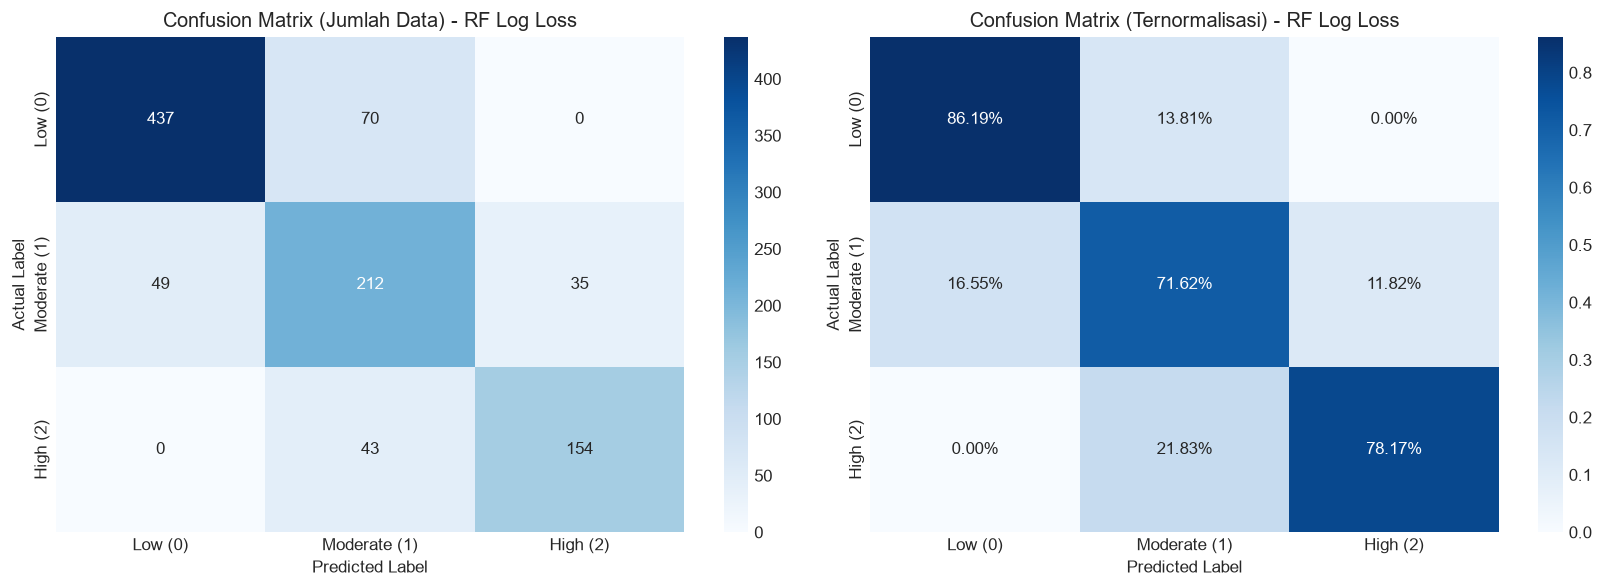

In [25]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Raw counts
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=target_names,
    yticklabels=target_names,
    ax=axes[0]
)
axes[0].set_title('Confusion Matrix (Jumlah Data) - RF Log Loss')
axes[0].set_xlabel('Predicted Label')
axes[0].set_ylabel('Actual Label')

# Normalized
cm_norm = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis]
sns.heatmap(
    cm_norm,
    annot=True,
    fmt='.2%',
    cmap='Blues',
    xticklabels=target_names,
    yticklabels=target_names,
    ax=axes[1]
)
axes[1].set_title('Confusion Matrix (Ternormalisasi) - RF Log Loss')
axes[1].set_xlabel('Predicted Label')
axes[1].set_ylabel('Actual Label')

plt.tight_layout()
plt.savefig(f'{OUTPUT_DIR}/confusion_matrix_log_loss.png')
plt.show()

### 5.2 Visualisasi Distribusi Kelas Prediksi vs Aktual

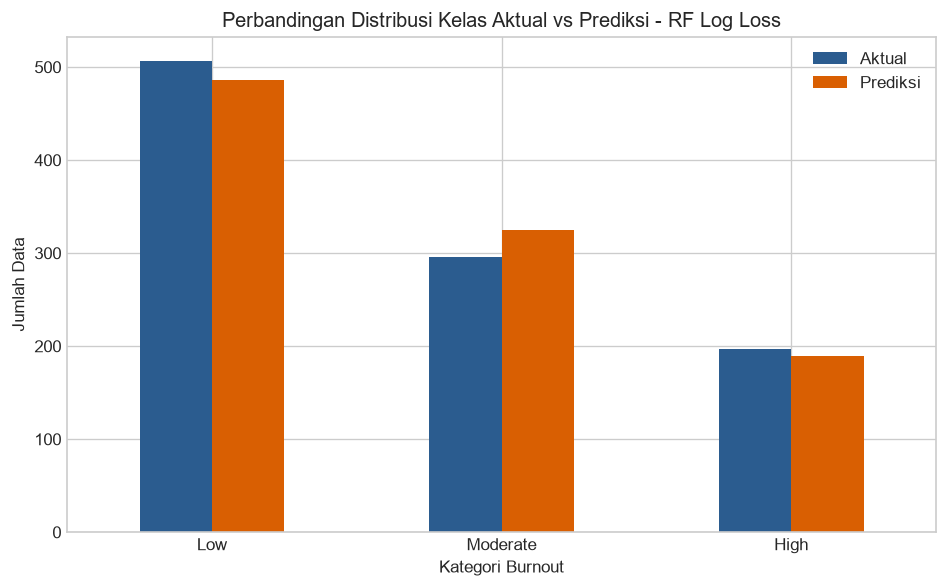

In [26]:
df_dist = pd.DataFrame(
    {
        'Aktual': y_test.map({0: 'Low', 1: 'Moderate', 2: 'High'}).value_counts(),
        'Prediksi': pd.Series(y_pred, index=y_test.index).map({0: 'Low', 1: 'Moderate', 2: 'High'}).value_counts()
    }
)

df_dist.plot(
    kind='bar',
    figsize=(8, 5),
    color=['#2b5c8f', '#d95f02']
)

plt.title('Perbandingan Distribusi Kelas Aktual vs Prediksi - RF Log Loss')
plt.xlabel('Kategori Burnout')
plt.ylabel('Jumlah Data')
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig(f'{OUTPUT_DIR}/class_distribution_log_loss.png')
plt.show()

### 5.3 Visualisasi Metrik Evaluasi per Fold (Cross-Validation)

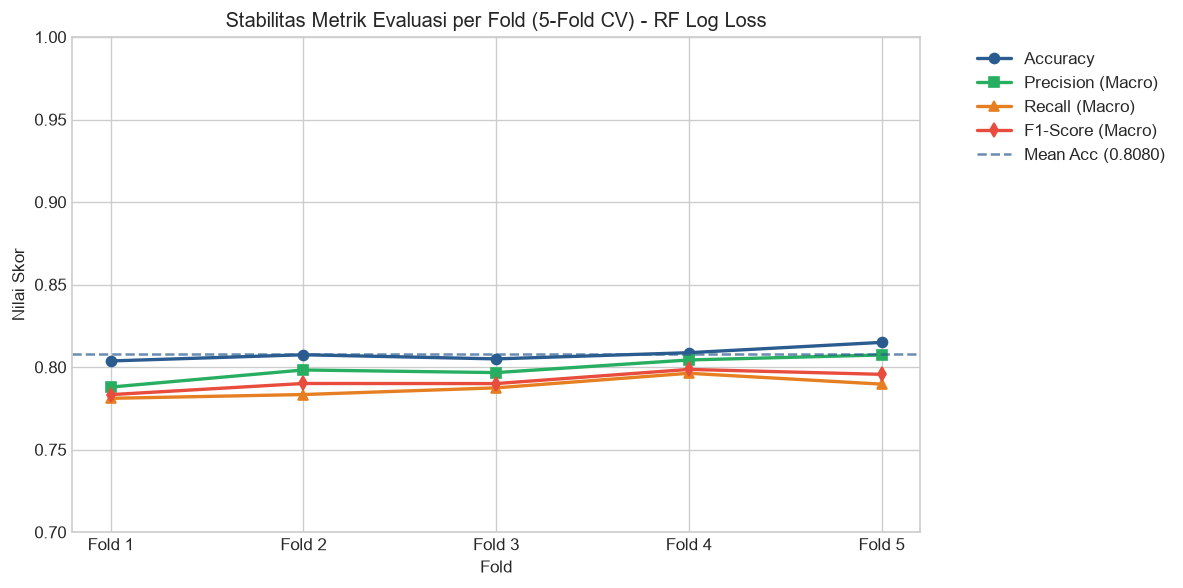

In [27]:
df_folds = df_cv.iloc[:5].copy()
if 'Fold' not in df_folds.columns:
    df_folds['Fold'] = [f'Fold {i+1}' for i in range(len(df_folds))]

plt.figure(figsize=(10, 5))
plt.plot(df_folds['Fold'], df_folds['Accuracy'], marker='o', label='Accuracy', color='#2b5c8f', linewidth=2)
plt.plot(df_folds['Fold'], df_folds['Precision (Macro)'], marker='s', label='Precision (Macro)', color='#27ae60', linewidth=2)
plt.plot(df_folds['Fold'], df_folds['Recall (Macro)'], marker='^', label='Recall (Macro)', color='#e67e22', linewidth=2)
plt.plot(df_folds['Fold'], df_folds['F1-Score (Macro)'], marker='d', label='F1-Score (Macro)', color='#e74c3c', linewidth=2)

mean_acc = float(df_cv.loc['Mean', 'Accuracy']) if 'Mean' in df_cv.index else float(df_folds['Accuracy'].mean())
plt.axhline(mean_acc, color='#2b5c8f', linestyle='--', alpha=0.7, label=f"Mean Acc ({mean_acc:.4f})")
plt.title('Stabilitas Metrik Evaluasi per Fold (5-Fold CV) - RF Log Loss')
plt.xlabel('Fold')
plt.ylabel('Nilai Skor')
plt.ylim(0.7, 1.0)
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.savefig(f'{OUTPUT_DIR}/cv_metrics_per_fold_log_loss.png')
plt.show()

### 5.4 Visualisasi Top 10 Feature Importance

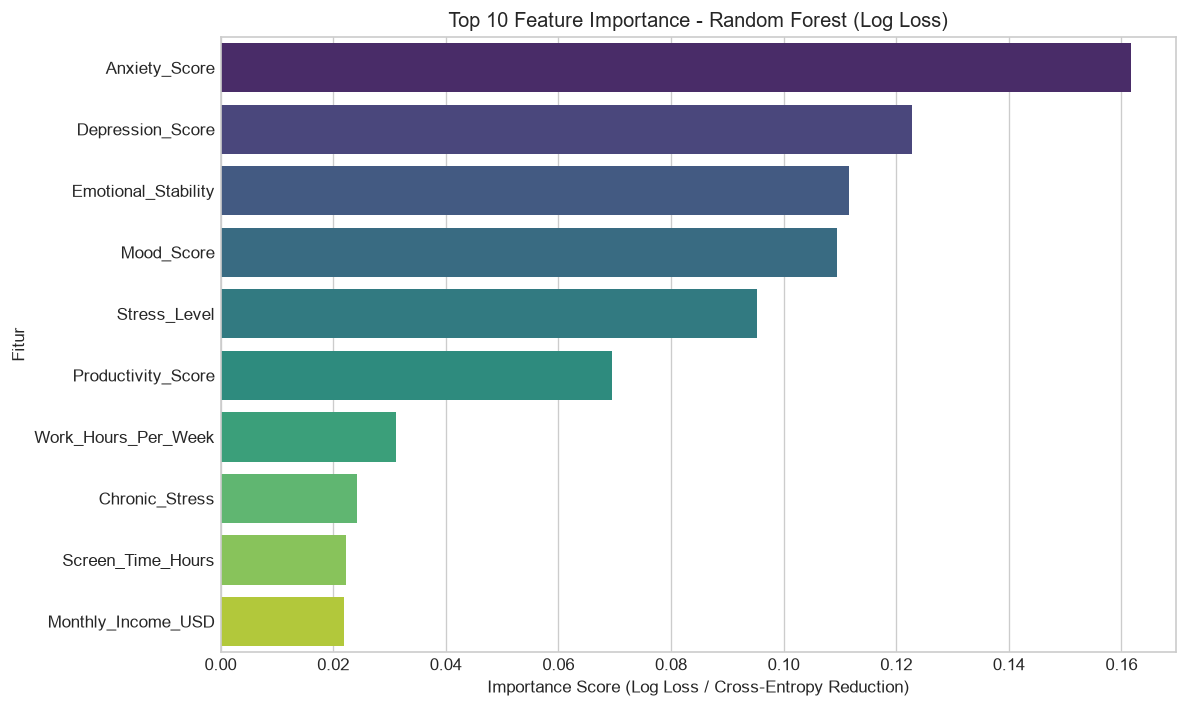

In [28]:
importances = pd.Series(model.feature_importances_, index=X_train.columns).sort_values(ascending=False).head(10)

plt.figure(figsize=(10, 6))
sns.barplot(x=importances.values, y=importances.index, palette='viridis')
plt.title('Top 10 Feature Importance - Random Forest (Log Loss)')
plt.xlabel('Importance Score (Log Loss / Cross-Entropy Reduction)')
plt.ylabel('Fitur')
plt.tight_layout()
plt.savefig(f'{OUTPUT_DIR}/feature_importance_log_loss.png')
plt.show()

## 6. Analisis Tambahan / Analisis Parameter

### 6.1 Analisis Pengaruh Nilai n_estimators terhadap Akurasi & Waktu

,n_estimators,Train_Accuracy,Test_Accuracy,Test_F1_Macro,Training_Time_s
0,10,0.98675,0.796,0.772552,0.140625
1,50,1.00000,0.804,0.788613,0.546875
2,100,1.00000,0.803,0.786953,1.265625
3,200,1.00000,0.804,0.787316,1.984375


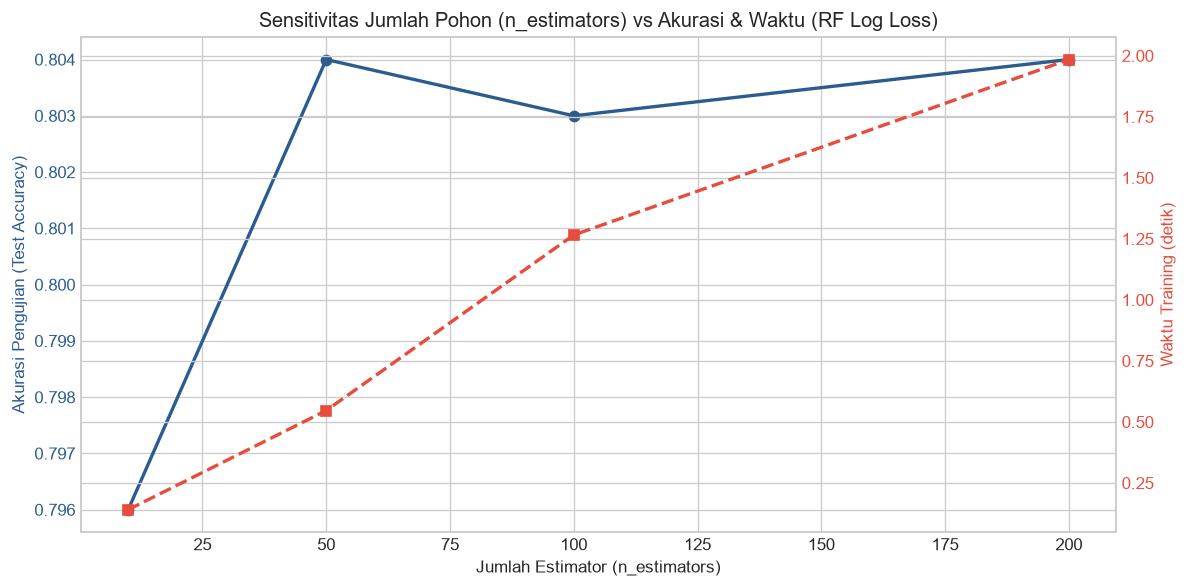

In [29]:
n_est_list = [10, 50, 100, 200]
results_nest = []

for n in n_est_list:
    t0 = time.process_time()
    rf_temp = RandomForestClassifier(
        criterion='log_loss',
        n_estimators=n,
        random_state=42,
        n_jobs=-1
    )
    rf_temp.fit(X_train, y_train)
    t_train = time.process_time() - t0
    
    y_tr_pred = rf_temp.predict(X_train)
    y_ts_pred = rf_temp.predict(X_test)
    
    results_nest.append({
        'n_estimators': n,
        'Train_Accuracy': accuracy_score(y_train, y_tr_pred),
        'Test_Accuracy': accuracy_score(y_test, y_ts_pred),
        'Test_F1_Macro': f1_score(y_test, y_ts_pred, average='macro'),
        'Training_Time_s': t_train
    })

df_nest_analysis = pd.DataFrame(results_nest)
display(df_nest_analysis)

fig, ax1 = plt.subplots(figsize=(10, 5))

color = '#2b5c8f'
ax1.set_xlabel('Jumlah Estimator (n_estimators)')
ax1.set_ylabel('Akurasi Pengujian (Test Accuracy)', color=color)
ax1.plot(
    df_nest_analysis['n_estimators'],
    df_nest_analysis['Test_Accuracy'],
    marker='o',
    color=color,
    linewidth=2,
    label='Test Accuracy'
)
ax1.tick_params(axis='y', labelcolor=color)

ax2 = ax1.twinx()
color = '#e74c3c'
ax2.set_ylabel('Waktu Training (detik)', color=color)
ax2.plot(
    df_nest_analysis['n_estimators'],
    df_nest_analysis['Training_Time_s'],
    marker='s',
    linestyle='--',
    color=color,
    linewidth=2,
    label='Training Time (s)'
)
ax2.tick_params(axis='y', labelcolor=color)

plt.title('Sensitivitas Jumlah Pohon (n_estimators) vs Akurasi & Waktu (RF Log Loss)')
fig.tight_layout()
plt.savefig(f'{OUTPUT_DIR}/nest_sensitivity_log_loss.png')
plt.show()

## 7. Ekspor File

### 7.1 Ekspor Ringkasan Evaluasi

In [30]:
evaluation_result.to_csv(
    f'{OUTPUT_DIR}/metrics_rf_log_loss.csv',
    index=False
)

### 7.2 Ekspor Hasil Prediksi Data Uji

In [31]:
df_prediksi.to_csv(
    f'{OUTPUT_DIR}/predictions_rf_log_loss.csv'
)

### 7.3 Ekspor Hasil 5-Fold Cross-Validation

In [32]:
df_cv.to_csv(
    f'{OUTPUT_DIR}/cv_5fold_rf_log_loss.csv'
)

### 7.4 Ekspor Hasil Analisis Estimator

In [33]:
df_nest_analysis.to_csv(
    f'{OUTPUT_DIR}/nest_analysis_rf_log_loss.csv',
    index=False
)

### 7.5 Ekspor Feature Importance

In [34]:
importances.to_frame(name='Importance').to_csv(
    f'{OUTPUT_DIR}/feature_importance_rf_log_loss.csv'
)